In [1]:
import pandas as pd
import geopandas as gpd
import statsmodels.api as sm
import statsmodels.stats.diagnostic as smd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import jarque_bera
from libpysal.weights import Queen
import libpysal
from esda.moran import Moran
from splot.esda import moran_scatterplot 
from spreg import OLS as spreg_OLS
from spreg import ML_Lag, ML_Error, GM_Combo_Het, GM_Lag
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
harita_yolu = "../data/tur_admin1.shp"  # Bkz. data/README.md
veri_yolu = "../data/veri.xlsx"

In [2]:
# Veriyi okutuyoruz
df = pd.read_excel(veri_yolu)
df.head()

,YIL,BÖLGE KODU,BÖLGE ADI,"İş kayıtlarına göre girişim sayıları : Mesleki, bilimsel ve teknik faaliyetler",Adrese Dayalı Nüfus Kayıt Sistemine göre nüfus yoğunluğu : Nüfus yoğunluğu (kilometrekareye düşen kişi sayısı),Ortalama hanehalkı büyüklüğü : Ortalama hanehalkı büyüklüğü,Hanehalkı tiplerine göre hanehalkı sayısı : Toplam,Hanehalkı tiplerine göre hanehalkı sayısı : Tek kişilik hanehalkı,Adrese Dayalı Nüfus Kayıt Sistemine göre yaş bağımlılık oranı : 15-64 yaş grubu nüfus,Adrese Dayalı Nüfus Kayıt Sistemine göre cinsiyet oranı : Erkek nüfus,...,Yaş gruplarına göre boşanma sayıları : Kadın / 75 ve üzeri,Şekline göre intiharlar : Tren veya başka motorlu bir araç altına atlayarak / Erkek,Yaş gruplarına göre evlenme sayıları : Gelin / 75 ve üzeri,Yaş gruplarına göre boşanma sayıları : Kadın / Bilinmeyen,Cinsiyet ve yaş gruplarına göre intihar sayıları : Kadın / Bilinmeyen,Şekline göre intiharlar : Tren veya başka motorlu bir araç altına atlayarak / Kadın,Yaş gruplarına göre evlenme sayıları : Gelin / Bilinmeyen,Şekline göre intiharlar : Diğer / Toplam,Şekline göre intiharlar : Diğer / Erkek,Şekline göre intiharlar : Diğer / Kadın
0,2024,TR100,İstanbul,109299,2934,3.1,4855719,943363,11352421,7820462,...,22,11,19,265,-,2,-,11,10,1
1,2024,TR211,Tekirdağ,3515,191,3.0,381082,71397,828688,604896,...,2,-,-,9,-,-,-,2,1,1
2,2024,TR212,Edirne,1440,69,2.6,150672,37664,288961,211611,...,2,-,-,7,-,-,-,-,-,-
3,2024,TR213,Kırklareli,1042,59,2.7,135272,31376,261107,192109,...,2,-,1,3,-,-,-,-,-,-
4,2024,TR221,Balıkesir,4082,90,2.6,473746,119432,854168,633993,...,7,-,5,14,-,-,-,3,2,1


In [3]:
# Sütun isimleri çok uzun olduğu için analize uygun şekilde kısaltıyoruz
df = df.rename(columns={
    'BÖLGE ADI': 'Il_Adi',
    'İş kayıtlarına göre girişim sayıları : Mesleki, bilimsel ve teknik faaliyetler': 'Girisim_Sayisi',
    'Adrese Dayalı Nüfus Kayıt Sistemine göre nüfus yoğunluğu  : Nüfus yoğunluğu (kilometrekareye düşen kişi sayısı)': 'Nufus_Yogunlugu',
    'Adrese Dayalı Nüfus Kayıt Sistemine göre il ve ilçe merkezleri ile belde ve köyler nüfusu ve nüfus artış hızı : İl ve ilçe merkezleri nüfusunun toplam nüfus içindeki oranı (%)': 'Sehirlesme_Orani',
    'Cinsiyete göre genç nüfus : Genç nüfusun (15-24 yaş grubu) toplam nüfus içindeki oranı (%)': 'Genc_Nufus_Orani'
})

In [4]:
# Oransal etkiye geçiş için log dönüşüm uyguluyoruz.
df['ln_Girisim'] = np.log(df['Girisim_Sayisi'])
df['ln_Nufus_Yog'] = np.log(df['Nufus_Yogunlugu'])

In [5]:
print(df[['Il_Adi', 'ln_Girisim', 'ln_Nufus_Yog', 'Sehirlesme_Orani', 'Genc_Nufus_Orani']].head())

       Il_Adi  ln_Girisim  ln_Nufus_Yog  Sehirlesme_Orani  Genc_Nufus_Orani
0    İstanbul   11.601843      7.984122            100.00              14.8
1    Tekirdağ    8.164795      5.252273            100.00              13.3
2      Edirne    7.272398      4.234107             76.48              13.8
3  Kırklareli    6.948897      4.077537             73.79              12.5
4   Balıkesir    8.314342      4.499810            100.00              11.8


In [6]:
tr_harita = gpd.read_file(harita_yolu)
# queen harita üzerinden sınır köşe komşuluğunu hesaplıyor.
w = Queen.from_dataframe(tr_harita)
#row standardized
w.transform = 'R' 
print("Mekansal Ağırlık Matrisi (W) Başarıyla Oluşturuldu ve Standardize Edildi.")

Mekansal Ağırlık Matrisi (W) Başarıyla Oluşturuldu ve Standardize Edildi.


In [7]:
# harita yolundaki isimlerin eşleşmesi adına düzeltmeler yapıyoruz ki boşluk, küçük harf vs. ayrımları olmasın hata almayalım.
def isim_duzelt(isim):
    if pd.isna(isim): return ""
    # Hepsini büyük harf yap ve boşlukları sil
    s = str(isim).upper().strip()
    # Türkçe karakterleri standartlaştır
    s = s.replace('İ', 'I').replace('Ş', 'S').replace('Ğ', 'G')
    s = s.replace('Ç', 'C').replace('Ö', 'O').replace('Ü', 'U')
    if s == "AFYON": s = "AFYONKARAHISAR"
    return s

In [8]:
#harita ve veri setinde isimleri düzeltiyoruz.
tr_harita['temiz_ad'] = tr_harita['adm1_name'].apply(isim_duzelt)
df['temiz_ad'] = df['Il_Adi'].apply(isim_duzelt)

In [9]:
# birleştirme
df_final = tr_harita.merge(df, on='temiz_ad')
# kontrol
print(f"Başarıyla eşleşen il sayısı: {len(df_final)}")

Başarıyla eşleşen il sayısı: 81


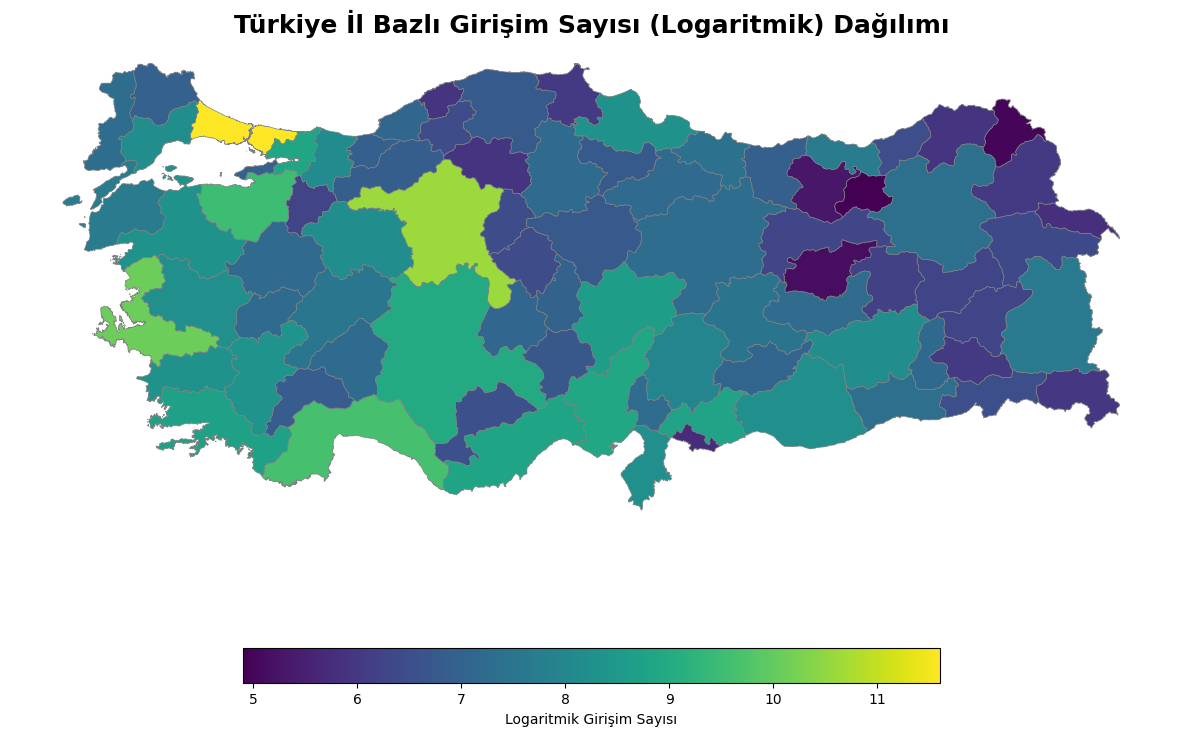

In [10]:
# görselleştirmeden önce hata almamak adına koşul oluşturarak check ediyoruz ve görselleştiriyoruz
if len(df_final) > 0:
    fig, ax = plt.subplots(1, 1, figsize=(15, 10))
    
    df_final.plot(column='ln_Girisim', 
                  ax=ax, 
                  legend=True, 
                  legend_kwds={'label': 'Logaritmik Girişim Sayısı', 'orientation': 'horizontal', 'shrink': 0.6}, 
                  cmap='viridis', 
                  edgecolor='gray', 
                  linewidth=0.5)
    
    plt.title('Türkiye İl Bazlı Girişim Sayısı (Logaritmik) Dağılımı', fontsize=18, fontweight='bold')
    plt.axis('off')
    plt.show()
else:
    print("Eşleşme başarısız.")

In [11]:
# Bağımlı (y) ve Bağımsız (X) değişkenler
y_name = 'ln_Girisim'
X_names = ['ln_Nufus_Yog', 'Sehirlesme_Orani', 'Genc_Nufus_Orani']
y = df_final[y_name].values.reshape(-1, 1)
X_df = df_final[X_names]
X = X_df.values

In [12]:
# ols yapabilmek için statsmodele verimiz için constant ekliyoruz.
X_sm = sm.add_constant(X_df)
print("Değişkenler modellere girmeye hazır!")

Değişkenler modellere girmeye hazır!


In [13]:
#Mekansallık yokmuş gibi OLS modelimizi kuruyoruz ve mekansallık durumu için testlerimizi gerçekleştiriyoruz.
ols_model = sm.OLS(df_final[y_name], X_sm).fit()
print("="*60)
print("1. KLASİK OLS (EN KÜÇÜK KARELER) SONUÇLARI")
print("="*60)
print(ols_model.summary())

print("\n--- VIF (Variance Inflation Factor) Değerleri ---")
for i in range(1, X_sm.shape[1]):
    vif_val = variance_inflation_factor(X_sm.values, i)
    print(f"{X_sm.columns[i]}: {vif_val:.4f}")

jb_test = jarque_bera(ols_model.resid)
print("\n--- Normallik Testi (Jarque-Bera) ---")
print(f"JB İstatistiği: {jb_test[0]:.4f}, p-değeri: {jb_test[1]:.4f}")

bp_test = smd.het_breuschpagan(ols_model.resid, X_sm)
white_test = smd.het_white(ols_model.resid, X_sm)
print("\n--- Değişen Varyans Testleri ---")
print(f"Breusch-Pagan p-değeri : {bp_test[1]:.4f}")
print(f"White Testi p-değeri   : {white_test[1]:.4f}")

reset_test = smd.linear_reset(ols_model, power=2, test_type="fitted")
print("\n--- Ramsey RESET Testi ---")
print(f"F-istatistiği (Statistic): {reset_test.statistic:.4f}, p-değeri: {reset_test.pvalue:.4f}")

1. KLASİK OLS (EN KÜÇÜK KARELER) SONUÇLARI
                            OLS Regression Results                            
Dep. Variable:             ln_Girisim   R-squared:                       0.771
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     86.26
Date:                Mon, 18 May 2026   Prob (F-statistic):           1.48e-24
Time:                        00:42:18   Log-Likelihood:                -72.494
No. Observations:                  81   AIC:                             153.0
Df Residuals:                      77   BIC:                             162.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------

In [14]:
print("\n" + "="*60)
print("2. MEKANSAL EKONOMETRİK MODELLER (SPREG)")
print("="*60)

# A. SPREG İLE OLS VE MEKANSAL LM TESTLERİ
sp_ols = spreg_OLS(y, X, w=w, name_y=y_name, name_x=X_names, spat_diag=True, moran=True)
print("\n--- SPREG OLS ve Mekansal Teşhis (LM) Testleri ---")
print(sp_ols.summary)

# B. SAR (SPATIAL AUTOREGRESSIVE MODEL)
sar_model = ML_Lag(y, X, w=w, name_y=y_name, name_x=X_names)
print("\n--- SAR (Mekansal Gecikme Modeli) ML Tahmini ---")
print(sar_model.summary)

# C. SEM (SPATIAL ERROR MODEL)
sem_model = ML_Error(y, X, w=w, name_y=y_name, name_x=X_names)
print("\n--- SEM (Mekansal Hata Modeli) ML Tahmini ---")
print(sem_model.summary)

# D. SDM (SPATIAL DURBIN MODEL)
WX = libpysal.weights.lag_spatial(w, X)
WX_names = ['W_' + name for name in X_names]
X_SDM = np.hstack((X, WX))
X_SDM_names = X_names + WX_names

sdm_model = ML_Lag(y, X_SDM, w=w, name_y=y_name, name_x=X_SDM_names)
print("\n--- SDM (Mekansal Durbin Modeli) ML Tahmini ---")
print(sdm_model.summary)

# E. SAC / SARAR MODELİ
sac_model = GM_Combo_Het(y, X, w=w, name_y=y_name, name_x=X_names)
print("\n--- SAC / SARAR Modeli (GMM Tahmini) ---")
print(sac_model.summary)

# F. GS2SLS VE ROBUST TAHMİNLER
gs2sls_robust = GM_Lag(y, X, w=w, name_y=y_name, name_x=X_names, robust='white')
print("\n--- GS2SLS Robust (Araç Değişken ve Dirençli Standart Hata) ---")
print(gs2sls_robust.summary)


2. MEKANSAL EKONOMETRİK MODELLER (SPREG)

--- SPREG OLS ve Mekansal Teşhis (LM) Testleri ---
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :  ln_Girisim                Number of Observations:          81
Mean dependent var  :      7.2936                Number of Variables   :           4
S.D. dependent var  :      1.2443                Degrees of Freedom    :          77
R-squared           :      0.7707
Adjusted R-squared  :      0.7618
Sum squared residual:     28.4048                F-statistic           :     86.2643
Sigma-square        :       0.369                Prob(F-statistic)     :   1.481e-24
S.E. of regression  :       0.607                Log likelihood        :     -72.494
Sigma-square ML     :       0.351                Akaike info criterion :     152.989
S.E of re


3. MEKANSAL OTOKORELASYON (MORAN'S I) ANALİZİ
Moran's I İstatistiği: 0.2536
P-değeri: 0.0010


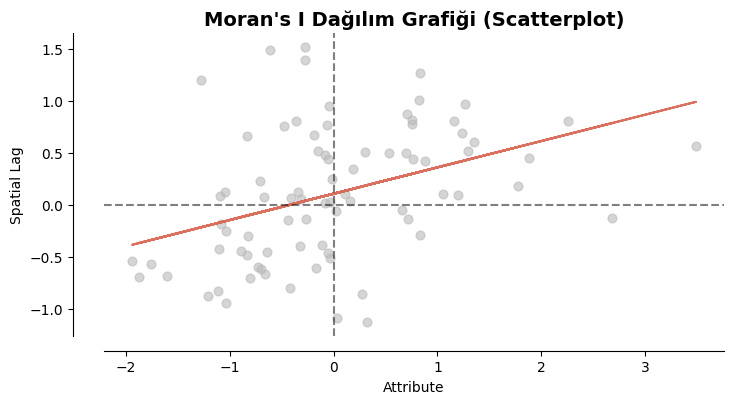

In [15]:
# Sadece bağımlı değişken (Girişim Sayısı) üzerinden Moran's I hesaplıyoruz
moran = Moran(df_final[y_name], w)

print("\n" + "="*60)
print("3. MEKANSAL OTOKORELASYON (MORAN'S I) ANALİZİ")
print("="*60)
print(f"Moran's I İstatistiği: {moran.I:.4f}")
print(f"P-değeri: {moran.p_sim:.4f}")
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
moran_scatterplot(moran, ax=ax)
ax.set_title("Moran's I Dağılım Grafiği (Scatterplot)", fontsize=14, fontweight='bold')
plt.show()


3. MEKANSAL OTOKORELASYON (GLOBAL MORAN'S I) ANALİZİ
Moran's I İstatistiği: 0.2536
P-değeri: 0.0010
Z-Skoru: 3.8042


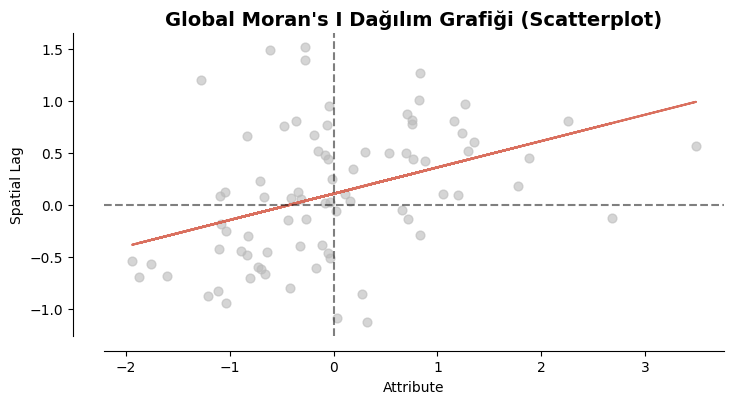

In [16]:
# Sadece bağımlı değişken (Girişim Sayısı) üzerinden Moran's I hesaplıyoruz
moran = Moran(df_final[y_name], w)

print("\n" + "="*60)
print("3. MEKANSAL OTOKORELASYON (GLOBAL MORAN'S I) ANALİZİ")
print("="*60)
print(f"Moran's I İstatistiği: {moran.I:.4f}")
print(f"P-değeri: {moran.p_sim:.4f}")
print(f"Z-Skoru: {moran.z_sim:.4f}") # EKSİK OLAN Z-SKORU EKLENDİ

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
moran_scatterplot(moran, ax=ax)
ax.set_title("Global Moran's I Dağılım Grafiği (Scatterplot)", fontsize=14, fontweight='bold')
plt.show()


4. LOKAL MEKANSAL OTOKORELASYON (LISA) ANALİZİ
Aşağıdaki harita, Türkiye'deki girişim sayılarının lokal bazda nerelerde
anlamlı bir şekilde kümelendiğini (High-High, Low-Low vb.) göstermektedir.


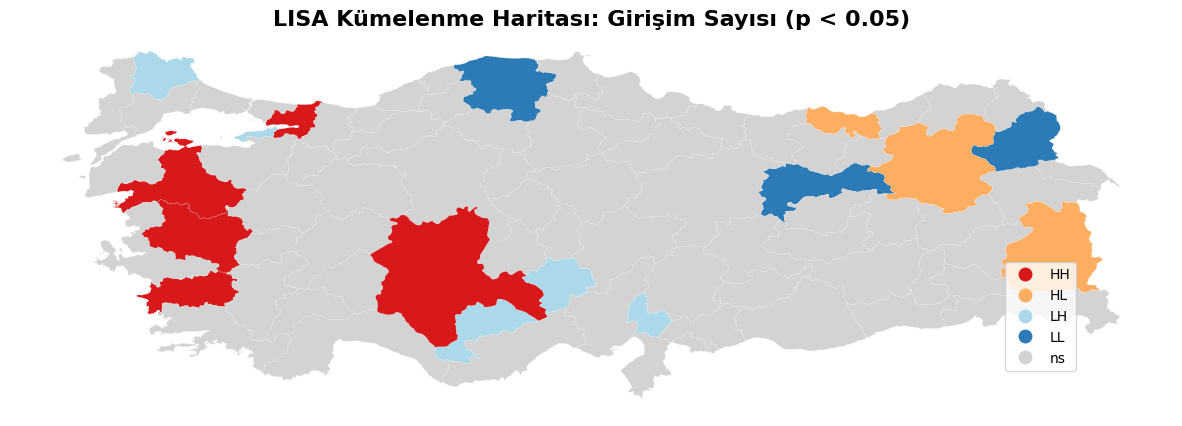

In [17]:
from esda.moran import Moran_Local
from splot.esda import lisa_cluster

# Lokal Moran's I (LISA) Analizi (Değişken Bazında Mekansal Kümelenme)
moran_loc = Moran_Local(df_final[y_name], w)

print("\n" + "="*60)
print("4. LOKAL MEKANSAL OTOKORELASYON (LISA) ANALİZİ")
print("="*60)
print("Aşağıdaki harita, Türkiye'deki girişim sayılarının lokal bazda nerelerde")
print("anlamlı bir şekilde kümelendiğini (High-High, Low-Low vb.) göstermektedir.")

# LISA Kümelenme Haritası
fig, ax = plt.subplots(figsize=(15, 10))
lisa_cluster(moran_loc, df_final, p=0.05, ax=ax, 
             legend_kwds={'loc': 'lower left', 'bbox_to_anchor': (0.85, 0.1)})
ax.set_title("LISA Kümelenme Haritası: Girişim Sayısı (p < 0.05)", fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()


5. MODEL KARŞILAŞTIRMASI (BİLGİ KRİTERLERİ - AIC) VE KALINTI HARİTALARI
OLS Modeli AIC Değeri : 152.99
SAR Modeli AIC Değeri : 154.98
SEM Modeli AIC Değeri : 151.39
SDM Modeli AIC Değeri : 139.46

BİLİMSEL YORUM:
Bilgi Kriterlerine (AIC) göre en düşük değere sahip olan model en iyi uyumu sağlar.
Yukarıdaki sonuçlara göre Mekansal Durbin Modeli (SDM) en düşük AIC değerine sahiptir.
------------------------------------------------------------


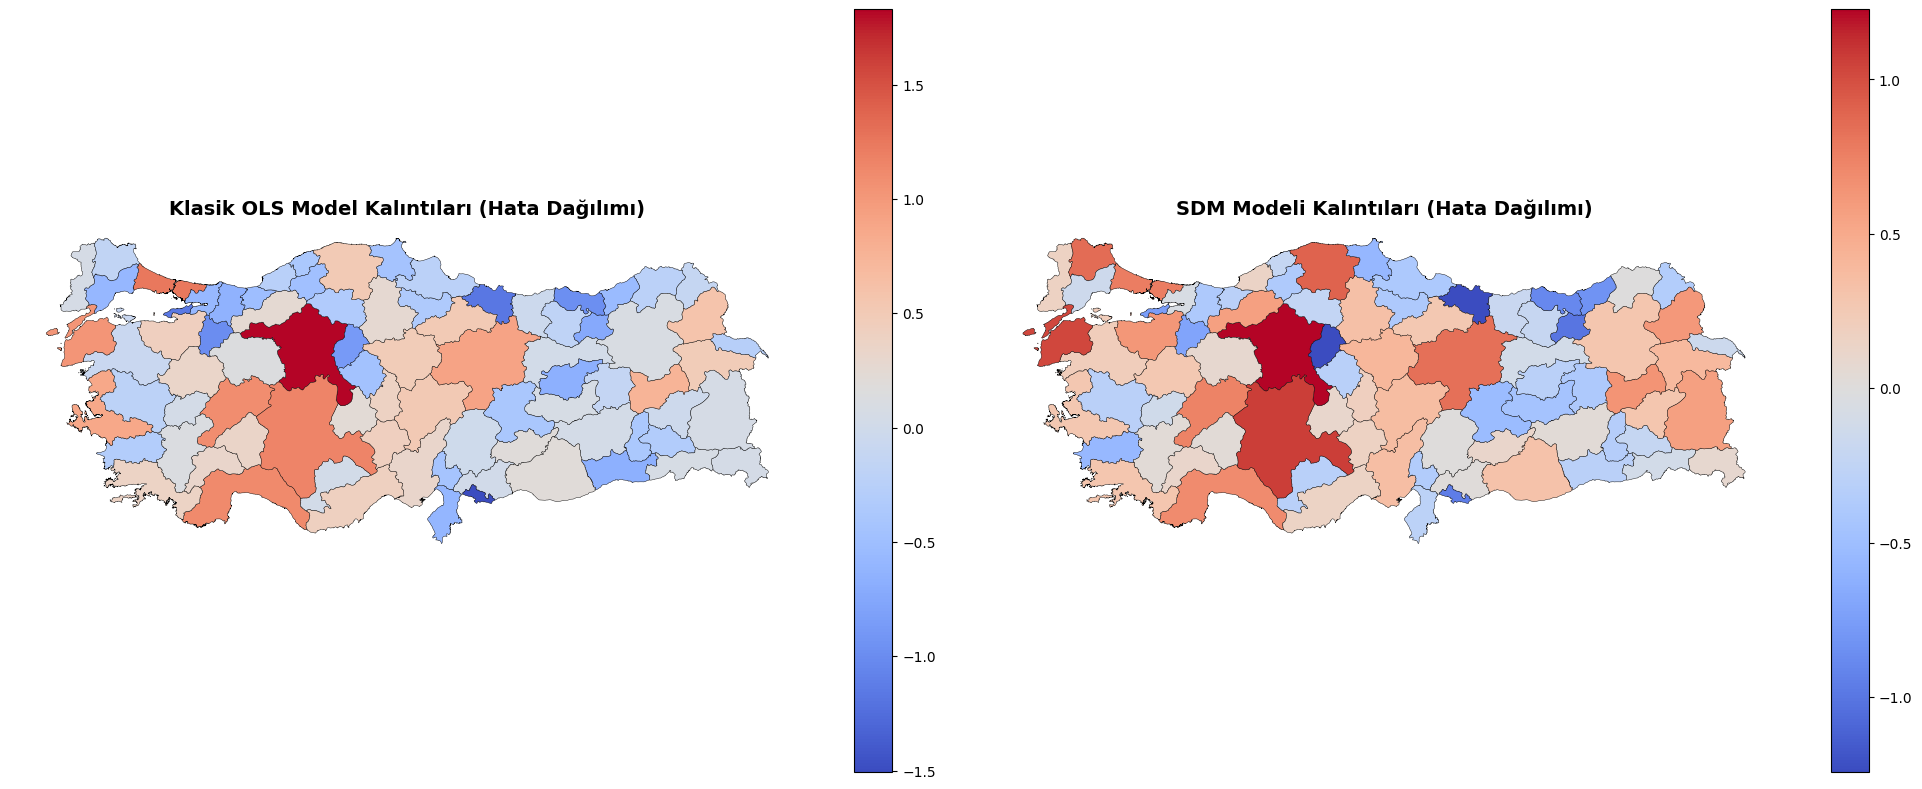

In [18]:
print("\n" + "="*60)
print("5. MODEL KARŞILAŞTIRMASI (BİLGİ KRİTERLERİ - AIC) VE KALINTI HARİTALARI")
print("="*60)

# Modellerin AIC değerlerini çekip kıyaslıyoruz
print(f"OLS Modeli AIC Değeri : {ols_model.aic:.2f}")
print(f"SAR Modeli AIC Değeri : {sar_model.aic:.2f}")
print(f"SEM Modeli AIC Değeri : {sem_model.aic:.2f}")
print(f"SDM Modeli AIC Değeri : {sdm_model.aic:.2f}")

print("\nBİLİMSEL YORUM:")
print("Bilgi Kriterlerine (AIC) göre en düşük değere sahip olan model en iyi uyumu sağlar.")
print("Yukarıdaki sonuçlara göre Mekansal Durbin Modeli (SDM) en düşük AIC değerine sahiptir.")
print("-" * 60)

# OLS ve En İyi Model (SDM) Kalıntılarını (Residuals) Haritaya Ekleme
# Spreg modellerinde kalıntılar '.u' içinde, statsmodels'de '.resid' içindedir.
df_final['OLS_Residuals'] = ols_model.resid
df_final['SDM_Residuals'] = sdm_model.u.flatten() # 2D array'i 1D'ye çeviriyoruz

# Kalıntı (Hata) Haritalarını Yan Yana Çizdirme
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. OLS Kalıntı Haritası
df_final.plot(column='OLS_Residuals', ax=axes[0], cmap='coolwarm', 
              legend=True, edgecolor='black', linewidth=0.3)
axes[0].set_title('Klasik OLS Model Kalıntıları (Hata Dağılımı)', fontsize=14, fontweight='bold')
axes[0].axis('off')

# 2. SDM Kalıntı Haritası
df_final.plot(column='SDM_Residuals', ax=axes[1], cmap='coolwarm', 
              legend=True, edgecolor='black', linewidth=0.3)
axes[1].set_title('SDM Modeli Kalıntıları (Hata Dağılımı)', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()